# Deep Learning, Phase 2 (CNNs), Day 5: Famous Architectures and Residual Connections
So far we designed our own small CNNs. Today we look at the three architectures every CNN course mentions, and build the key idea of the last one, the **residual block**.
1. A short history: LeNet, VGG, ResNet  2. Counting parameters  3. The residual block  4. ResNet-20 vs the same network without skip connections  5. Final test evaluation (once)  6. A real ResNet-18 from `torchvision`

Set the GPU first: Runtime > Change runtime type > **T4 GPU**. Plan about 10 minutes of training.

In [1]:
import copy, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
sns.set_theme(style='whitegrid')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)
if device == 'cpu': print('WARNING: no GPU found, training will be very slow. Runtime > Change runtime type > T4 GPU.')
torch.manual_seed(0); np.random.seed(0)

Using device: cuda


In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)           # CIFAR-10 channel means and stds (R, G, B)
tf_plain = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_aug = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomCrop(32, padding=4),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def cifar(train, transform):
    return datasets.CIFAR10('data', train=train, download=True, transform=transform)

full_plain, full_aug, test_set = cifar(True, tf_plain), cifar(True, tf_aug), cifar(False, tf_plain)      # test set stays locked
n = len(full_plain); n_val = n // 10
perm = torch.randperm(n, generator=torch.Generator().manual_seed(0)).tolist()
val_idx, train_idx = perm[:n_val], perm[n_val:]
train_plain = Subset(full_plain, train_idx)      # training images, no augmentation
train_aug   = Subset(full_aug, train_idx)        # SAME training images, with random augmentation
val_set     = Subset(full_plain, val_idx)        # validation: never augmented
print('Train:', len(train_idx), '| Validation:', len(val_idx), '| Test (locked):', len(test_set))

val_dl, test_dl = DataLoader(val_set, batch_size=512, num_workers=2), DataLoader(test_set, batch_size=512, num_workers=2)
make_train_dl = lambda ds: DataLoader(ds, batch_size=128, shuffle=True, num_workers=2)
unnorm = lambda t: (t * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0)

100%|██████████| 170M/170M [22:10<00:00, 128kB/s]


Train: 45000 | Validation: 5000 | Test (locked): 10000


In [3]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, dl):
    model.eval(); tot = correct = n = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot / n, correct / n

def train(model, train_dl, epochs=15, lr=1e-3, cosine=False, name=''):
    model.to(device); opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_dl)) if cosine else None
    hist = {'loss': [], 'val_loss': [], 'val_acc': [], 'time': []}; best, best_state, best_ep = float('inf'), None, 0
    for ep in range(epochs):
        t0 = time.time(); model.train(); run = n = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            if sched: sched.step()
            run += loss.item() * len(yb); n += len(yb)
        vl, va = evaluate(model, val_dl)
        for k, v in zip(hist, (run / n, vl, va, time.time() - t0)): hist[k].append(v)
        if vl < best: best, best_state, best_ep = vl, copy.deepcopy(model.state_dict()), ep + 1
        print(f'{name} epoch {ep + 1:2d}/{epochs}  train loss {run / n:.3f}  val loss {vl:.3f}  val acc {va:.3f}  ({time.time() - t0:.1f}s)')
    model.load_state_dict(best_state); hist['best_epoch'] = best_ep
    print(f'{name}: restored the best epoch ({best_ep})'); return hist

n_params = lambda m: sum(p.numel() for p in m.parameters())
EPOCHS = 15

## 1. Three landmark architectures
| Architecture | Year | Main idea | Size |
|---|---|---|---|
| **LeNet-5** | 1998 | The first CNN: conv, pool, conv, pool, then dense layers. Read handwritten digits. | tiny (about 60 thousand parameters) |
| **VGG** | 2014 | Very uniform: **stacks of 3x3 convolutions** followed by pooling, repeated. Two 3x3 convs cover the same area as one 5x5 with fewer parameters. | huge dense layers (VGG-16 has 138 million parameters) |
| **ResNet** | 2015 | **Skip (residual) connections** let very deep networks (50, 101, 152 layers) train. Won ImageNet 2015. | ResNet-18 has 11.7 million parameters |

Why were skip connections needed? Making a plain network deeper should not hurt, but in practice very deep plain networks became **harder to train** (the training error went *up*, not only the test error). The gradient has to travel back through many layers and the optimisation gets difficult. A skip connection gives the signal and the gradient a direct path.

Let's write all three as small versions and count parameters.

In [4]:
lenet = nn.Sequential(                                         # LeNet-5 style, for 3x32x32 input
    nn.Conv2d(3, 6, 5), nn.ReLU(), nn.MaxPool2d(2),            # -> (6, 14, 14)
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),           # -> (16, 5, 5)
    nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.ReLU(), nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10))

def vgg_block(i, o, n_convs):                                  # VGG idea: n_convs 3x3 convs, then pool
    layers = []
    for k in range(n_convs): layers += [nn.Conv2d(i if k == 0 else o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
    return layers + [nn.MaxPool2d(2)]
mini_vgg = nn.Sequential(*vgg_block(3, 32, 2), *vgg_block(32, 64, 2), *vgg_block(64, 128, 2),          # 32 -> 16 -> 8 -> 4
                         nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 10))
for name, m in [('LeNet-5 style', lenet), ('Mini-VGG (3 blocks of 2 convs)', mini_vgg)]:
    out = m(torch.zeros(2, 3, 32, 32)); print(f'{name:32s} output {tuple(out.shape)}  parameters: {n_params(m):,}')

LeNet-5 style                    output (2, 10)  parameters: 62,006
Mini-VGG (3 blocks of 2 convs)   output (2, 10)  parameters: 815,018


## 2. The residual block
A normal block computes `y = F(x)`. A **residual block** computes **`y = F(x) + x`**: the block only has to learn the *change* (the residual) on top of its input. If the best thing to do is nothing, it only has to learn F(x) = 0, which is easy. The `+ x` also gives gradients a direct path back during backpropagation.

Inside the block: Conv3x3 -> BatchNorm -> ReLU -> Conv3x3 -> BatchNorm, **add the input**, then ReLU. When the block changes the number of channels or the size (stride 2), the input must be reshaped to match before adding, which a 1x1 convolution does (the *shortcut*).

We add a `residual` switch, so that we can build the **same network without the skip connection** for an honest comparison.

In [5]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Sequential()
        if stride != 1 or c_in != c_out:                                       # shapes differ: reshape the input with a 1x1 conv
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))
    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual: out = out + self.shortcut(x)                         # the skip connection:  F(x) + x
        return torch.relu(out)

class ResNetCifar(nn.Module):
    """CIFAR-style ResNet with 6n+2 layers: n=3 gives ResNet-20, n=9 gives ResNet-56."""
    def __init__(self, n=3, residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        layers, c_in = [], 16
        for c_out, stride in [(16, 1), (32, 2), (64, 2)]:                      # three stages: 32x32 -> 16x16 -> 8x8
            for k in range(n): layers.append(BasicBlock(c_in, c_out, stride if k == 0 else 1, residual)); c_in = c_out
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10))
    def forward(self, x): return self.head(self.stages(self.stem(x)))

def make_net(n=3, residual=True, seed=0):
    torch.manual_seed(seed); return ResNetCifar(n, residual)

block = BasicBlock(16, 32, stride=2)
print('A block with a changing shape: input (1,16,32,32) ->', tuple(block(torch.zeros(1, 16, 32, 32)).shape))
for res in (True, False):
    net = make_net(3, res); print(f"{'ResNet-20' if res else 'Plain-20 (no skips)':20s} output {tuple(net(torch.zeros(2, 3, 32, 32)).shape)}  parameters: {n_params(net):,}")

A block with a changing shape: input (1,16,32,32) -> (1, 32, 16, 16)
ResNet-20            output (2, 10)  parameters: 272,474
Plain-20 (no skips)  output (2, 10)  parameters: 272,474


The two networks have **exactly the same layers and number of parameters**. The only difference is the `+ x`.

## 3. ResNet-20 vs Plain-20: same depth, with and without skip connections
Both trained on augmented CIFAR-10 with the same settings and seed.

In [6]:
N_BLOCKS = 3                  # 6n+2 layers: 3 -> 20 layers. Try 9 (56 layers) only if you have GPU time to spare
res_net = make_net(N_BLOCKS, residual=True);  h_res = train(res_net, make_train_dl(train_aug), epochs=EPOCHS, cosine=True, name='ResNet')

ResNet epoch  1/15  train loss 1.492  val loss 1.357  val acc 0.520  (20.7s)
ResNet epoch  2/15  train loss 1.069  val loss 1.154  val acc 0.610  (20.2s)
ResNet epoch  3/15  train loss 0.896  val loss 0.913  val acc 0.683  (18.9s)
ResNet epoch  4/15  train loss 0.786  val loss 0.996  val acc 0.669  (20.2s)
ResNet epoch  5/15  train loss 0.708  val loss 0.721  val acc 0.750  (18.9s)
ResNet epoch  6/15  train loss 0.647  val loss 0.643  val acc 0.772  (19.1s)
ResNet epoch  7/15  train loss 0.593  val loss 0.648  val acc 0.771  (20.0s)
ResNet epoch  8/15  train loss 0.553  val loss 0.595  val acc 0.790  (19.0s)
ResNet epoch  9/15  train loss 0.512  val loss 0.639  val acc 0.783  (20.5s)
ResNet epoch 10/15  train loss 0.483  val loss 0.518  val acc 0.819  (19.2s)
ResNet epoch 11/15  train loss 0.462  val loss 0.479  val acc 0.835  (20.3s)
ResNet epoch 12/15  train loss 0.431  val loss 0.461  val acc 0.839  (19.0s)
ResNet epoch 13/15  train loss 0.413  val loss 0.460  val acc 0.838  (20.0s)

In [7]:
plain_net = make_net(N_BLOCKS, residual=False); h_plain = train(plain_net, make_train_dl(train_aug), epochs=EPOCHS, cosine=True, name='Plain')

Plain epoch  1/15  train loss 1.666  val loss 1.418  val acc 0.471  (19.6s)
Plain epoch  2/15  train loss 1.272  val loss 1.551  val acc 0.505  (18.7s)
Plain epoch  3/15  train loss 1.076  val loss 1.023  val acc 0.632  (20.0s)
Plain epoch  4/15  train loss 0.942  val loss 0.866  val acc 0.694  (18.5s)
Plain epoch  5/15  train loss 0.841  val loss 0.998  val acc 0.673  (19.2s)
Plain epoch  6/15  train loss 0.765  val loss 0.770  val acc 0.734  (19.1s)
Plain epoch  7/15  train loss 0.700  val loss 0.685  val acc 0.763  (18.7s)
Plain epoch  8/15  train loss 0.653  val loss 0.648  val acc 0.773  (20.1s)
Plain epoch  9/15  train loss 0.609  val loss 0.622  val acc 0.787  (18.7s)
Plain epoch 10/15  train loss 0.571  val loss 0.585  val acc 0.796  (23.1s)
Plain epoch 11/15  train loss 0.534  val loss 0.552  val acc 0.806  (18.7s)
Plain epoch 12/15  train loss 0.509  val loss 0.533  val acc 0.816  (20.5s)
Plain epoch 13/15  train loss 0.488  val loss 0.522  val acc 0.817  (18.5s)
Plain epoch 

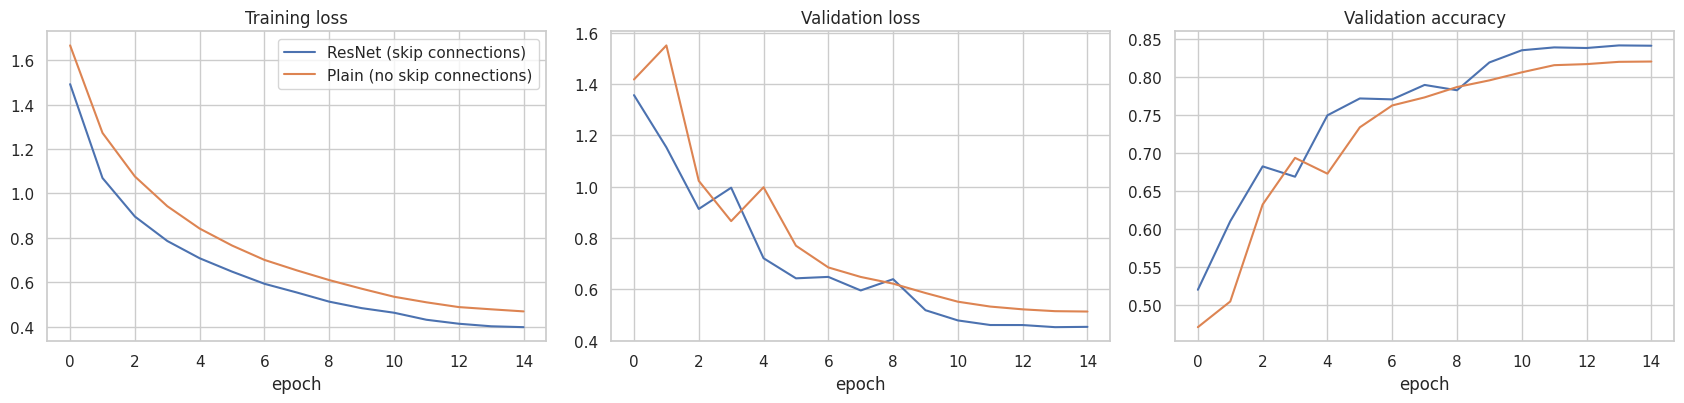

,parameters,best epoch,train loss (last epoch),val loss,val acc,seconds / epoch
ResNet,272474.0,14.0,0.3974,0.4522,0.8418,19.6555
Plain,272474.0,15.0,0.4684,0.5132,0.8206,19.4540


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for name, h in [('ResNet (skip connections)', h_res), ('Plain (no skip connections)', h_plain)]:
    ax[0].plot(h['loss'], label=name); ax[1].plot(h['val_loss'], label=name); ax[2].plot(h['val_acc'], label=name)
ax[0].set(title='Training loss', xlabel='epoch'); ax[1].set(title='Validation loss', xlabel='epoch'); ax[2].set(title='Validation accuracy', xlabel='epoch'); ax[0].legend()
plt.tight_layout(); plt.show()
v_res, v_plain = evaluate(res_net, val_dl), evaluate(plain_net, val_dl)
pd.DataFrame({'ResNet': {'parameters': n_params(res_net), 'best epoch': h_res['best_epoch'], 'train loss (last epoch)': h_res['loss'][-1], 'val loss': v_res[0], 'val acc': v_res[1], 'seconds / epoch': np.mean(h_res['time'])},
              'Plain': {'parameters': n_params(plain_net), 'best epoch': h_plain['best_epoch'], 'train loss (last epoch)': h_plain['loss'][-1], 'val loss': v_plain[0], 'val acc': v_plain[1], 'seconds / epoch': np.mean(h_plain['time'])}}).T.round(4)



**Honest reading:** with batch normalization, even a plain 20-layer network trains reasonably well, so the difference here is usually **modest**. The dramatic gap in the original ResNet paper appears at 50 to 100+ layers (a plain 56-layer network was *worse* than a plain 20-layer one). If you have GPU time, set `N_BLOCKS = 9` (56 layers) and compare again. Differences smaller than about 0.5 points on a 5,000-image validation set are noise.

## 4. Final test evaluation (once)
Chosen on the validation loss; the 10,000 test images are scored once.

In [9]:
chosen_name, chosen = ('ResNet', res_net) if v_res[0] <= v_plain[0] else ('Plain', plain_net)
print('Chosen on the validation set:', chosen_name)
test_loss, test_acc = evaluate(chosen, test_dl); print(f'TEST accuracy: {test_acc:.4f}   TEST loss: {test_loss:.4f}')
torch.save(chosen.state_dict(), 'cifar_resnet20.pt')

Chosen on the validation set: ResNet
TEST accuracy: 0.8395   TEST loss: 0.4765


## 5. A real ResNet-18 from `torchvision`
`torchvision.models` contains the famous architectures. We load the **structure only** (`weights=None`, no download). Tomorrow we load the **pretrained weights** for transfer learning.

In [10]:
from torchvision import models
r18 = models.resnet18(weights=None)
print(r18)
print('\nResNet-18 parameters:', f'{n_params(r18):,}')

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [11]:
rows = {'LeNet-5 style (CIFAR)': n_params(lenet), 'Mini-VGG (ours)': n_params(mini_vgg), 'ResNet-20 (ours)': n_params(res_net), 'ResNet-18 (torchvision)': n_params(r18)}
rows['VGG-11 (torchvision)'] = n_params(models.vgg11(weights=None))
pd.Series(rows, name='parameters').to_frame().assign(millions=lambda d: (d['parameters'] / 1e6).round(2))

,parameters,millions
LeNet-5 style (CIFAR),62006,0.06
Mini-VGG (ours),815018,0.82
ResNet-20 (ours),272474,0.27
ResNet-18 (torchvision),11689512,11.69
VGG-11 (torchvision),132863336,132.86


**Look at the printout of ResNet-18:** it starts with a 7x7 convolution and a max pool (for 224x224 ImageNet images), then four stages of `BasicBlock`s (each has `conv1`, `bn1`, `conv2`, `bn2`, and a `downsample` shortcut when the shape changes: the same structure as our block), then an average pool and one `fc` layer with 1,000 outputs. In transfer learning we will replace that last `fc` layer.

